# 🚗 Vehicle Registration Trend Analysis
**Dataset:** Washington State Electric Vehicle Population Data (WA Dept. of Licensing) — ≈135,000 real registered vehicles, 17 columns.
**Goal:** study how registrations changed over time — BEV vs PHEV, makes, electric range, counties.

| CO | Unit | Topics |
|---|---|---|
| **CO1** | I | NumPy basics |
| **CO2** | II | Pandas basics, file reading/writing |
| **CO3** | III | Data cleaning, preparation and wrangling |
| **CO4** | IV | Group operations and time series |
| **CO5** | V | Matplotlib and Seaborn visualisation |

> The data is a snapshot of *currently registered* vehicles with no registration date, so **Model Year** is used as the time axis (trend analysis covers 2010–2023).

In [1]:
import os, re, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

DATA_FILE = "Electric_Vehicle_Population_Data.csv"
DATA_URL = "https://raw.githubusercontent.com/BogdanRivera/Electric_vehicle/main/Electric_Vehicle_Population_Data.csv"
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
os.makedirs("outputs", exist_ok=True)
print("ready:", DATA_FILE)

ready: Electric_Vehicle_Population_Data.csv


---
# 🔵 CO1 — NumPy Basics *(Unit I)*

In [2]:
# 1.1 Creating ndarrays  |  1.2 Data types
num = pd.read_csv(DATA_FILE, usecols=["Model Year", "Electric Range", "Base MSRP"])
year, rng_mi, msrp = (num[c].to_numpy() for c in num.columns)
print(year[:5], year.dtype, year.shape, year.ndim)
print(np.zeros((2, 3)), np.arange(2010, 2014), np.linspace(0, 1, 5), np.eye(2), sep="\n")
y16 = year.astype(np.int16)
print(f"int64 {year.nbytes/1e6:.1f} MB -> int16 {y16.nbytes/1e6:.1f} MB | float->int:", np.array([3.7, -1.2]).astype(int))

[2019 2022 2020 2020 2013] int64 (135038,) 1
[[0. 0. 0.]
 [0. 0. 0.]]
[2010 2011 2012 2013]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0.]
 [0. 1.]]
int64 1.1 MB -> int16 0.3 MB | float->int: [ 3 -1]


In [3]:
# 1.3 Arithmetic (vectorised, broadcasting)
age = 2024 - year
rng_km = rng_mi * 1.609344
print(age[:5], rng_km[:3].round(1))
print(np.array([[0], [10], [20]]) + np.array([1, 2, 3]))        # broadcasting (3,1)+(3,) -> (3,3)

# 1.4 Basic indexing and slicing (slices are views)
X = np.column_stack((year, rng_mi, msrp))
print(X.shape, X[:3], X[::40000, 0], X[:3, 1:], sep="\n")
v = year[:5].copy(); v[:2][:] = -1; print("view edit:", v)

[ 5  2  4  4 11] [354.1   0.  428.1]
[[ 1  2  3]
 [11 12 13]
 [21 22 23]]
(135038, 3)
[[2019.  220.    0.]
 [2022.    0.    0.]
 [2020.  266.    0.]]
[2019. 2018. 2018. 2020.]
[[220.   0.]
 [  0.   0.]
 [266.   0.]]
view edit: [  -1   -1 2020 2020 2013]


In [4]:
# 1.5 Boolean indexing
recent = year >= 2020
long_rng = (year >= 2018) & (rng_mi >= 250)
print("MY>=2020:", recent.sum(), "| MY>=2018 & range>=250:", long_rng.sum())
print("mean range 2020+ vs older (known only):", rng_mi[recent & (rng_mi > 0)].mean().round(1), rng_mi[~recent & (rng_mi > 0)].mean().round(1))
print(dict(zip(*np.unique(np.where(rng_mi >= 250, "Long", np.where(rng_mi > 0, "Short", "Unknown")), return_counts=True))))

# 1.6 Fancy indexing
print(X[[0, 100, 5000]], X[np.ix_([0, 1], [0, 2])], sep="\n")
top5 = np.argsort(-rng_mi)[:5]; print("top-5 ranges:", rng_mi[top5])

MY>=2020: 80194 | MY>=2018 & range>=250: 8933
mean range 2020+ vs older (known only): 134.2 126.9
{np.str_('Long'): np.int64(9060), np.str_('Short'): np.int64(68994), np.str_('Unknown'): np.int64(56984)}
[[2019.  220.    0.]
 [2017.   14.    0.]
 [2013.   38.    0.]]
[[2019.    0.]
 [2022.    0.]]
top-5 ranges: [337. 337. 337. 337. 337.]


In [5]:
# 1.7 Transposing arrays and swapping axes
mask = (year >= 2010) & (year <= 2023)
cnt = np.bincount(year[mask] - 2010)
table = np.vstack([np.arange(2010, 2024), cnt])
print(table.shape, "->", table.T.shape); print(table.T[:3])
a3 = np.arange(24).reshape(2, 3, 4)
print(a3.swapaxes(0, 2).shape, a3.transpose(1, 0, 2).shape, (X[:100, :2].T @ X[:100, :2]).shape)

# 1.8 Pseudo-random numbers
rng = np.random.default_rng(42)
print(rng.random(3).round(3), rng.integers(1, 100, 5), rng.normal(0, 1, 3).round(3))
valid = rng_mi[rng_mi > 0]
sample = rng.choice(valid, 5000, replace=False)
boot = rng.choice(sample, (1000, 5000)).mean(axis=1)
print(f"population mean {valid.mean():.1f} | sample {sample.mean():.1f} | 95% bootstrap CI {np.percentile(boot, [2.5, 97.5]).round(1)}")

# 1.9 Universal functions
r5 = valid[:5]
print(np.sqrt(r5).round(2), np.log1p(r5).round(2), np.maximum(r5, 200), np.clip(valid[:6], 0, 100))
yrs, c = np.unique(year[mask], return_counts=True)
print(pd.DataFrame({"model_year": yrs[1:], "vehicles": c[1:], "yoy_%": (np.diff(c) / c[:-1] * 100).round(1)}).tail(6).to_string(index=False))

(2, 14) -> (14, 2)
[[2010   23]
 [2011  815]
 [2012 1657]]
(4, 3, 2) (3, 2, 4) (2, 2)
[0.774 0.439 0.859] [ 9 70 20 10 53] [ 0.128 -0.316 -0.017]
population mean 129.0 | sample 128.9 | 95% bootstrap CI [126.2 131.6]
[14.83 16.31 17.94 14.42  9.85] [5.4  5.59 5.78 5.34 4.58] [220. 266. 322. 208. 200.] [100. 100. 100. 100.  97. 100.]
 model_year  vehicles  yoy_%
       2018     14343  67.20
       2019     10577 -26.30
       2020     11151   5.40
       2021     18554  66.40
       2022     27983  50.80
       2023     22476 -19.70


---
# 🟢 CO2 — Pandas Basics and Data Loading/Storage *(Unit II)*

In [6]:
# 2.1 Series, DataFrame, Index
df = pd.read_csv(DATA_FILE)
print(df.shape)
s = pd.Series([61808, 13150], index=["TESLA", "NISSAN"], name="vehicles"); print(s, s["TESLA"])
try: df.columns[0] = "x"
except TypeError as e: print("Index is immutable:", e)
display(df.head(3))

(135038, 17)
TESLA     61808
NISSAN    13150
Name: vehicles, dtype: int64 61808
Index is immutable: Index does not support mutable operations


,VIN (1-10),Country,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EA0K,Thurston,Tumwater,WA,"98,512.00",2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.00,0.00,22.00,242565116,POINT (-122.91310169999997 47.01359260000004),PUGET SOUND ENERGY INC,"53,067,010,910.00"
1,1N4BZ1DV4N,Island,Clinton,WA,"98,236.00",2022,NISSAN,LEAF,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.00,0.00,10.00,183272785,POINT (-122.35936399999997 47.97965520000008),PUGET SOUND ENERGY INC,"53,029,972,000.00"
2,5YJ3E1EA0L,Snohomish,Snohomish,WA,"98,290.00",2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,266.00,0.00,44.00,112552366,POINT (-122.09150499999998 47.91555500000004),PUGET SOUND ENERGY INC,"53,061,052,502.00"


In [7]:
# 2.2 Reindexing  |  2.3 Dropping entries
by_year = df["Model Year"].value_counts().sort_index()
print(by_year.reindex(range(1995, 2000), fill_value=0).to_dict(), "| ffill:", pd.Series(["a", "b"], index=[0, 2]).reindex(range(4), method="ffill").tolist())
print(by_year.drop([1997, 2024]).shape, df.drop(columns=["VIN (1-10)", "Vehicle Location"]).shape, df.head(3).drop(index=[0, 1]).index.tolist())

# 2.4 Indexing, selection, filtering
print(df.loc[0:2, "Make":"Model"], df.iloc[:2, :3], sep="\n")
print("Tesla 2022:", len(df[(df["Make"] == "TESLA") & (df["Model Year"] == 2022)]), "| BMW/Audi:", df["Make"].isin(["BMW", "AUDI"]).sum(),
      "| Kia >200mi:", len(df.query("Make == 'KIA' and `Electric Range` > 200")))

{1995: 0, 1996: 0, 1997: 1, 1998: 1, 1999: 4} | ffill: ['a', 'a', 'b', 'b']
(20,) (135038, 15) [2]
     Make    Model
0   TESLA  MODEL 3
1  NISSAN     LEAF
2   TESLA  MODEL 3
   VIN (1-10)   Country      City
0  5YJ3E1EA0K  Thurston  Tumwater
1  1N4BZ1DV4N    Island   Clinton
Tesla 2022: 14191 | BMW/Audi: 8622 | Kia >200mi: 835


In [8]:
# 2.5 Arithmetic and data alignment
ct = pd.crosstab(df["Model Year"], df["Electric Vehicle Type"])
bev, phev = ct.iloc[:, 0], ct.iloc[:, 1]
print(pd.DataFrame({"BEV": bev, "PHEV": phev, "BEV %": (bev / (bev + phev) * 100).round(1)}).loc[2020:2023])
a, b = pd.Series([1, 2, 3], index=list("abc")), pd.Series([10, 20, 30], index=list("bcd"))
print((a + b).to_dict(), a.add(b, fill_value=0).to_dict())

# 2.6 Function application and mapping
print(df[["Model Year", "Electric Range", "Base MSRP"]].apply(lambda c: c.max() - c.min()).to_dict())
print(df["Electric Vehicle Type"].map({"Battery Electric Vehicle (BEV)": "BEV", "Plug-in Hybrid Electric Vehicle (PHEV)": "PHEV"}).value_counts().to_dict())
print(df.head(2).apply(lambda r: f"{r['Model Year']} {r['Make']} {r['Model']}", axis=1).tolist())

              BEV  PHEV  BEV %
Model Year                    
2020         9505  1646  85.20
2021        14970  3584  80.70
2022        23801  4182  85.10
2023        18622  3854  82.90
{'a': nan, 'b': 12.0, 'c': 23.0, 'd': nan} {'a': 1.0, 'b': 12.0, 'c': 23.0, 'd': 30.0}
{'Model Year': 27.0, 'Electric Range': 337.0, 'Base MSRP': 845000.0}
{'BEV': 103882, 'PHEV': 31156}
['2019 TESLA MODEL 3', '2022 NISSAN LEAF']


In [9]:
# 2.7 Sorting and ranking
print(df.sort_values(["Electric Range", "Model Year"], ascending=[False, False])[["Make", "Model", "Model Year", "Electric Range"]].head(3))
mk = df["Make"].value_counts(); print(pd.DataFrame({"vehicles": mk, "rank": mk.rank(ascending=False, method="min")}).head(3))
print({m: pd.Series([7, 7, 5]).rank(method=m).tolist() for m in ["average", "min", "dense", "first"]})

# 2.8 Duplicate labels on an axis
by_make = df.set_index("Make")[["Model"]]
print("unique index?", by_make.index.is_unique, "| loc['TESLA'] ->", by_make.loc["TESLA"].shape, "| sd['a'] ->", pd.Series(range(4), index=list("aabc"))["a"].tolist())

# 2.9 Descriptive statistics
print(df[["Model Year", "Electric Range", "Base MSRP"]].describe())
known_r = df.loc[df["Electric Range"] > 0, "Electric Range"]
print(known_r.agg(["mean", "median", "std", "skew"]).round(2).to_dict(), "|", (df["Make"].value_counts(normalize=True).head(3) * 100).round(1).to_dict())

       Make    Model  Model Year  Electric Range
619   TESLA  MODEL S        2020          337.00
3509  TESLA  MODEL S        2020          337.00
5569  TESLA  MODEL S        2020          337.00
           vehicles  rank
Make                     
TESLA         61808  1.00
NISSAN        13150  2.00
CHEVROLET     11437  3.00
{'average': [2.5, 2.5, 1.0], 'min': [2.0, 2.0, 1.0], 'dense': [2.0, 2.0, 1.0], 'first': [2.0, 3.0, 1.0]}
unique index? False | loc['TESLA'] -> (61808, 1) | sd['a'] -> [0, 1]
       Model Year  Electric Range  Base MSRP
count  135,038.00      135,037.00 135,037.00
mean     2,019.66           74.59   1,448.41
std          3.00           98.74   9,683.66
min      1,997.00            0.00       0.00
25%      2,018.00            0.00       0.00
50%      2,021.00           21.00       0.00
75%      2,022.00          150.00       0.00
max      2,024.00          337.00 845,000.00
{'mean': 129.05, 'median': 84.0, 'std': 99.2, 'skew': 0.33} | {'TESLA': 45.8, 'NISSAN': 9.7, 'C

In [10]:
# 2.10 Reading text files in pieces
tot, yc = 0, pd.Series(dtype="float64")
for i, ch in enumerate(pd.read_csv(DATA_FILE, chunksize=25_000, usecols=["Model Year"])):
    tot += len(ch); yc = yc.add(ch["Model Year"].value_counts(), fill_value=0)
print(f"{i+1} chunks, {tot:,} rows | equals full load:", np.array_equal(yc.sort_index().astype(int).to_numpy(), by_year.to_numpy()))
print(pd.read_csv(DATA_FILE, nrows=2, usecols=["Make", "Model"]))

# 2.11 Writing data to text format
smp = df.sample(1000, random_state=1)
smp.to_csv("outputs/ev_sample.csv", index=False)
smp[["Make", "Model"]].to_csv("outputs/make_model.tsv", sep="\t", index=False)
print(df[["Make", "Model"]].head(2).to_csv(index=False))
print("round trip OK:", pd.read_csv("outputs/ev_sample.csv").shape == smp.shape)

6 chunks, 135,038 rows | equals full load: True
     Make    Model
0   TESLA  MODEL 3
1  NISSAN     LEAF


Make,Model
TESLA,MODEL 3
NISSAN,LEAF

round trip OK: True


---
# 🟠 CO3 — Data Cleaning, Preparation and Wrangling *(Unit III)*

## Part A — Cleaning and preparation

In [11]:
# 3.1 Filtering out missing data
ev = df.copy()
m = ev.isna().sum(); print(m[m > 0].to_dict())
print("dropna rows left:", len(ev.dropna()), "| subset=['Model']:", len(ev.dropna(subset=["Model"])), "| axis=1 cols:", ev.dropna(axis=1).shape[1])

# 3.2 Filling in missing data
ev = ev.fillna({"Model": "UNKNOWN", "City": "UNKNOWN", "Electric Utility": "UNKNOWN", "Country": "UNKNOWN"})
ev["Base MSRP"] = ev["Base MSRP"].fillna(ev["Base MSRP"].median())
print(pd.Series([1, np.nan, np.nan, 4]).ffill().tolist(), pd.Series([1, np.nan, np.nan, 4]).interpolate().tolist())

# 3.3 Transforming data using a function or mapping
ev["ev_type"] = ev["Electric Vehicle Type"].map({"Battery Electric Vehicle (BEV)": "BEV", "Plug-in Hybrid Electric Vehicle (PHEV)": "PHEV"})
ev["vehicle_age"] = 2024 - ev["Model Year"]
def era(y): return "1 Early (<=2012)" if y <= 2012 else "2 Growth (2013-16)" if y <= 2016 else "3 Scale-up (2017-20)" if y <= 2020 else "4 Mainstream (2021+)"
ev["era"] = ev["Model Year"].apply(era)
print(ev["era"].value_counts().sort_index().to_dict())

{'Country': 8, 'City': 8, 'Postal Code': 8, 'Model': 249, 'Electric Range': 1, 'Base MSRP': 1, 'Legislative District': 312, 'Vehicle Location': 10, 'Electric Utility': 8, '2020 Census Tract': 8}
dropna rows left: 134474 | subset=['Model']: 134789 | axis=1 cols: 7
[1.0, 1.0, 1.0, 4.0] [1.0, 2.0, 3.0, 4.0]
{'1 Early (<=2012)': 2533, '2 Growth (2013-16)': 18812, '3 Scale-up (2017-20)': 44650, '4 Mainstream (2021+)': 69043}


In [12]:
# 3.4 Replacing values
col = "Clean Alternative Fuel Vehicle (CAFV) Eligibility"
ev["cafv"] = ev[col].replace({"Clean Alternative Fuel Vehicle Eligible": "Eligible", "Not eligible due to low battery range": "Not eligible",
                              "Eligibility unknown as battery range has not been researched": "Unknown"})
print(ev["cafv"].value_counts().to_dict())
ev[["Electric Range", "Base MSRP"]] = ev[["Electric Range", "Base MSRP"]].replace(0, np.nan)      # 0 = placeholder for "not recorded"
ev["range_raw"] = ev["Electric Range"]; ev["range_imputed"] = ev["Electric Range"].isna()
r = ev["Electric Range"]
for keys in (["Make", "Model"], ["Make", "ev_type"], ["ev_type"]):                                   # impute: most specific group first
    r = r.fillna(ev.groupby(keys)["Electric Range"].transform("median"))
ev["Electric Range"] = r
print(f"imputed {ev['range_imputed'].mean():.1%} of ranges | NaN left: {r.isna().sum()}")

{'Eligible': 61221, 'Unknown': 56983, 'Not eligible': 16834}


imputed 42.2% of ranges | NaN left: 0


> ⚠️ **Data-quality finding:** the DOL never researched the range of **battery-electric vehicles from model year 2021 onward** (recorded as 0). Imputed values are flagged in `range_imputed`; the original is kept in `range_raw`; range *trends* below use real values only (model year ≤ 2020).

In [13]:
# 3.5 Renaming axis indexes  (the source labels the county column "Country" by mistake)
ev = ev.rename(columns={"Country": "County", "VIN (1-10)": "VIN Prefix", col: "CAFV Eligibility"})
ev = ev.rename(columns=lambda c: re.sub(r"\W+", "_", c.strip().lower()).strip("_")).rename_axis("record_id")
ev["postal_code"] = ev["postal_code"].astype("Int64")
print(ev.columns.tolist())

# 3.6 Discretisation and binning
ev["range_band"] = pd.cut(ev["electric_range"], [0, 100, 200, 300, 1000], labels=["<100 mi", "100-200 mi", "200-300 mi", "300+ mi"])
print(ev["range_band"].value_counts(sort=False).to_dict())
print(pd.qcut(ev["electric_range"], 4).value_counts(sort=False).to_dict())

# 3.7 Detecting and filtering outliers
msrp_s = ev["base_msrp"].dropna(); z = (msrp_s - msrp_s.mean()) / msrp_s.std()
print("MSRP |z|>3:", (z.abs() > 3).sum(), ev.loc[z[z.abs() > 3].index, "model"].unique()[:4], "| years <2008:", (ev["model_year"] < 2008).sum(), "| outside WA:", (ev["state"] != "WA").sum())
ev = ev[ev["state"] == "WA"].copy()
print("rows after filtering:", len(ev))

['vin_prefix', 'county', 'city', 'state', 'postal_code', 'model_year', 'make', 'model', 'electric_vehicle_type', 'cafv_eligibility', 'electric_range', 'base_msrp', 'legislative_district', 'dol_vehicle_id', 'vehicle_location', 'electric_utility', '2020_census_tract', 'ev_type', 'vehicle_age', 'era', 'cafv', 'range_raw', 'range_imputed']


{'<100 mi': 48324, '100-200 mi': 9509, '200-300 mi': 74584, '300+ mi': 2621}
{Interval(5.999, 75.0, closed='right'): 35070, Interval(75.0, 215.0, closed='right'): 39783, Interval(215.0, 239.0, closed='right'): 27237, Interval(239.0, 337.0, closed='right'): 32948}
MSRP |z|>3: 12 <StringArray>
['PANAMERA', '918']
Length: 2, dtype: str | years <2008: 18 | outside WA: 312
rows after filtering: 134726


In [14]:
# 3.8 Categorical extension type and computations with categoricals
before = ev.memory_usage(deep=True).sum() / 1e6
cat_cols = ["make", "model", "county", "city", "ev_type", "cafv"]
for c in cat_cols: ev[c] = ev[c].astype("category")
ev["era"] = pd.Categorical(ev["era"], categories=sorted(ev["era"].unique()), ordered=True)
print(f"memory {before:.0f} MB -> {ev.memory_usage(deep=True).sum()/1e6:.0f} MB | ordered band >= '200-300 mi':", (ev["range_band"] >= "200-300 mi").sum())
print(ev.groupby("range_band", observed=True)["model_year"].mean().round(1).to_dict(), pd.get_dummies(ev["ev_type"]).sum().to_dict())
print("unused categories removed:", len(ev[ev["make"].isin(["TESLA", "BMW"])]["make"].cat.remove_unused_categories().cat.categories))

memory 129 MB -> 76 MB | ordered band >= '200-300 mi': 77035
{'<100 mi': 2018.2, '100-200 mi': 2019.3, '200-300 mi': 2020.6, '300+ mi': 2020.0} {'BEV': 103674, 'PHEV': 31052}
unused categories removed: 2


## Part B — Data wrangling
For trend analysis we keep model years **2010–2023** (`ev_t`).

In [15]:
ev_t = ev[ev["model_year"].between(2010, 2023)].copy()
for c in cat_cols + ["era", "range_band"]: ev_t[c] = ev_t[c].cat.remove_unused_categories()
print("trend dataset:", ev_t.shape)

# 3.9 Hierarchical indexing — reorder and sort levels  |  3.10 Summary statistics by level
hier = ev_t.groupby(["make", "model_year"], observed=True).size()
print(hier.loc["TESLA"].tail(3).to_dict(), "| 2022 top-3:", hier.xs(2022, level="model_year").nlargest(3).to_dict())
sw = hier.swaplevel().sort_index(); print(sw.loc[2023].nlargest(2).to_dict(), hier.reorder_levels(["model_year", "make"]).index.names)
print("per make:", hier.groupby(level="make").sum().nlargest(3).to_dict(), "| per year:", hier.groupby(level="model_year").sum().loc[2021:2023].to_dict())

# 3.11 Indexing with a DataFrame's columns
mm = ev_t.set_index(["make", "model"]).sort_index()
print(mm.loc[("TESLA", "MODEL Y")].shape, mm.reset_index().columns[:2].tolist())

trend dataset: (134659, 24)
{2021: 11193, 2022: 14158, 2023: 10496} | 2022 top-3: {'TESLA': 14158, 'KIA': 2084, 'FORD': 1747}
{'TESLA': 10496, 'CHEVROLET': 1445} ['model_year', 'make']
per make: {'TESLA': 61631, 'NISSAN': 13138, 'CHEVROLET': 11417} | per year: {2021: 18478, 2022: 27920, 2023: 22459}
(23531, 22) ['make', 'model']


In [16]:
# 3.12 Database-style joins and merging on index  (small hand-made lookup table)
origin = pd.DataFrame({"brand": ["TESLA", "NISSAN", "CHEVROLET", "FORD", "BMW", "KIA", "TOYOTA", "VOLKSWAGEN", "VOLVO", "AUDI", "HYUNDAI", "BYD"],
                       "origin_country": ["USA", "Japan", "USA", "USA", "Germany", "South Korea", "Japan", "Germany", "Sweden", "Germany", "South Korea", "China"]})
mc = ev_t.groupby("make", observed=True).size().rename("vehicles").reset_index(); mc["make"] = mc["make"].astype(str)
inner = mc.merge(origin, left_on="make", right_on="brand", how="inner")
left  = mc.merge(origin, left_on="make", right_on="brand", how="left")
outer = mc.merge(origin, left_on="make", right_on="brand", how="outer", indicator=True)
print(len(inner), len(left), len(outer), "| no origin:", left.loc[left["origin_country"].isna(), "make"].nunique(), "| lookup-only:", outer.loc[outer["_merge"] == "right_only", "brand"].tolist())
print(inner.groupby("origin_country")["vehicles"].sum().sort_values(ascending=False).to_dict())
print(mc.set_index("make").join(origin.set_index("brand"), how="inner").head(3))

# 3.13 Concatenating along an axis
bev_y = ev_t[ev_t["ev_type"] == "BEV"].groupby("model_year").size().rename("BEV")
phev_y = ev_t[ev_t["ev_type"] == "PHEV"].groupby("model_year").size().rename("PHEV")
print(pd.concat([bev_y, phev_y], axis=1).tail(2))
p1, p2 = (ev_t[ev_t["model_year"] == y].head(1)[["make", "model_year"]] for y in (2022, 2023))
print(pd.concat([p1, p2], keys=["MY22", "MY23"]))

11 35 36 | no origin: 24 | lookup-only: ['BYD']
{'USA': 79910, 'Japan': 17993, 'Germany': 12110, 'South Korea': 7874, 'Sweden': 3214}
           vehicles origin_country
make                              
AUDI           2719        Germany
BMW            5873        Germany
CHEVROLET     11417            USA
              BEV  PHEV
model_year             
2022        23755  4165
2023        18609  3850
                  make  model_year
     record_id                    
MY22 1          NISSAN        2022
MY23 26            BMW        2023


In [17]:
# 3.14 Combining data with overlap
x = pd.Series([np.nan, 2.5, np.nan, 3.5], index=list("fedc")); y = pd.Series([0., 1, 2, 3], index=list("fedc"))
print(x.combine_first(y).to_dict())
filled = ev_t["base_msrp"].combine_first(ev_t["make"].map(ev_t.groupby("make", observed=True)["base_msrp"].median()).astype(float))
print(f"MSRP available: {ev_t['base_msrp'].notna().mean():.1%} -> {filled.notna().mean():.1%}")

# 3.15 Reshaping with hierarchical indexing
tt = ev_t.groupby(["model_year", "ev_type"], observed=True).size()
wide = tt.unstack(); print(wide.tail(2), wide.stack().shape, sep="\n")
print(wide.reset_index().melt(id_vars="model_year", var_name="ev_type", value_name="vehicles").head(2))

{'f': 0.0, 'e': 2.5, 'd': 2.0, 'c': 3.5}
MSRP available: 2.5% -> 59.8%
ev_type       BEV  PHEV
model_year             
2022        23755  4165
2023        18609  3850
(28,)
   model_year ev_type  vehicles
0        2010     BEV        20
1        2011     BEV       740


---
# 🟣 CO4 — Aggregation, Group Operations and Time Series *(Unit IV)*

In [18]:
# 4.1 Column-wise and multiple-function application
ev_t["is_bev"] = ev_t["ev_type"] == "BEV"
g = ev_t.groupby("model_year")
print(g["range_raw"].agg(["mean", "median", "max", "count"]).loc[2018:2020])
print(g.agg({"range_raw": ["mean", "max"], "base_msrp": "median"}).loc[2019:2020])
yearly_stats = ev_t.groupby("model_year").agg(vehicles=("dol_vehicle_id", "count"), avg_range=("range_raw", "mean"), pct_bev=("is_bev", "mean"))
yearly_stats["pct_bev"] *= 100; print(yearly_stats.tail(4).round(1))

# 4.2 Aggregated data without row indexes
by_make = ev_t.groupby("make", as_index=False, observed=True).agg(vehicles=("dol_vehicle_id", "count")).sort_values("vehicles", ascending=False)
print(by_make.head(3))

             mean  median    max  count
model_year                             
2018       156.36  215.00 249.00  14314
2019       176.76  220.00 289.00  10552
2020       242.43  289.00 337.00  11062
           range_raw        base_msrp
                mean    max    median
model_year                           
2019          176.76 289.00 39,995.00
2020          242.43 337.00 81,100.00
            vehicles  avg_range  pct_bev
model_year                              
2020           11119     242.40    85.30
2021           18478      47.80    80.70
2022           27920      29.00    85.10
2023           22459      28.50    82.90
         make  vehicles
29      TESLA     61631
23     NISSAN     13138
5   CHEVROLET     11417


In [19]:
# 4.3 General split-apply-combine
for yr, grp in list(g)[:2]: print(yr, "->", len(grp))
mc3 = ev_t.groupby(["model_year", "make", "model"], observed=True).size().rename("vehicles").reset_index()
top2 = mc3.loc[mc3.groupby("model_year")["vehicles"].apply(lambda s: s.nlargest(2)).index.get_level_values(-1)]      # apply
print(top2[top2["model_year"] >= 2022].to_string(index=False))
mc3["share_%"] = mc3["vehicles"] / mc3.groupby("model_year")["vehicles"].transform("sum") * 100                       # transform
print(mc3.nlargest(2, "share_%").round(1).to_string(index=False))
print(pd.pivot_table(ev_t, values="range_raw", index="era", columns="ev_type", aggfunc="mean", observed=True).round(1))

2010 -> 23
2011 -> 815


 model_year  make   model  vehicles
       2022 TESLA MODEL Y      7589
       2022 TESLA MODEL 3      4974
       2023 TESLA MODEL Y      6890
       2023 TESLA MODEL 3      2903
 model_year   make    model  vehicles  share_%
       2011 NISSAN     LEAF       724    88.80
       2010  TESLA ROADSTER        20    87.00
ev_type                 BEV  PHEV
era                              
1 Early (<=2012)      91.70 23.70
2 Growth (2013-16)   124.10 30.10
3 Scale-up (2017-20) 225.80 33.40
4 Mainstream (2021+) 191.00 28.60


In [20]:
# 4.4 Date and time data types  |  4.5 String <-> datetime
from datetime import datetime, timedelta
print(datetime(2024, 5, 1).strftime("%d %b %Y"), datetime.strptime("2022-06-01", "%Y-%m-%d"), datetime(2023, 12, 31) - datetime(2020, 1, 1), pd.Timestamp("2022-03-15").day_name())
ev_t["model_date"] = pd.to_datetime(ev_t["model_year"].astype(str) + "-01-01", format="%Y-%m-%d")
print(ev_t["model_date"].head(2).tolist(), pd.to_datetime(["2020-01-01", "bad"], errors="coerce").tolist())

# 4.6 Time-series indexing, selection, subsetting
yearly = ev_t.groupby("model_date").size().asfreq("YS").rename("vehicles")
print(yearly["2018"].iloc[0], yearly["2015":"2018"].values, yearly[yearly.index.year >= 2021].values)

# 4.7 Time series with duplicate indices
dup = ev_t.set_index("model_date")["electric_range"].sort_index()
print("unique?", dup.index.is_unique, "| dup['2022'] rows:", len(dup["2022"]), "|", dup.groupby(level=0).mean().tail(2).round(1).to_dict())

01 May 2024 2022-06-01 00:00:00 1460 days, 0:00:00 Tuesday
[Timestamp('2019-01-01 00:00:00'), Timestamp('2022-01-01 00:00:00')] [Timestamp('2020-01-01 00:00:00'), NaT]
14314 [ 4910  5676  8558 14314] [18478 27920 22459]


unique? False | dup['2022'] rows: 27920 | {Timestamp('2022-01-01 00:00:00'): 191.3, Timestamp('2023-01-01 00:00:00'): 192.5}


In [21]:
# 4.8 Date ranges  |  4.9 Frequencies and date offsets
from pandas.tseries.offsets import MonthEnd, YearBegin, Day
print(pd.date_range("2024-01-01", periods=3, freq="MS").strftime("%Y-%m-%d").tolist(), pd.date_range("2024-01-01", periods=3, freq="W-SUN").strftime("%d %b").tolist(), pd.date_range("2024-01-01", periods=4, freq="2MS").strftime("%b").tolist())
d0 = pd.Timestamp("2022-05-17"); print(Day(3), (d0 + MonthEnd()).date(), (d0 + YearBegin()).date(), MonthEnd().rollback(d0).date())
print(pd.DataFrame({"now": yearly, "prev_year": yearly.shift(1)}).tail(2))

# 4.10 Resampling — down-sampling, up-sampling and interpolation
print(yearly.resample("5YS").agg(["sum", "mean"]))                               # down-sampling
growth = yearly.pct_change() * 100
y0, y1 = yearly.loc["2013-01-01"], yearly.loc["2022-01-01"]; cagr = (y1 / y0) ** (1 / 9) - 1
print(f"CAGR MY2013-2022 ({y0:,} -> {y1:,}): {cagr:.1%} | strongest growth since 2014: MY{growth.loc['2014':].idxmax().year}")
fleet = yearly.cumsum().rename("fleet_size")                                       # up-sampling: annual -> quarterly
print(fleet.resample("QS").asfreq().head(3).tolist(), "| ffill:", fleet.resample("QS").ffill().head(3).tolist())
print(fleet.resample("QS").interpolate("linear").loc["2020":"2020"].round(0).to_dict())

['2024-01-01', '2024-02-01', '2024-03-01'] ['07 Jan', '14 Jan', '21 Jan'] ['Jan', 'Mar', 'May', 'Jul']
<3 * Days> 2022-05-31 2023-01-01 2022-04-30
              now  prev_year
model_date                  
2022-01-01  27920  18,478.00
2023-01-01  22459  27,920.00
              sum      mean
model_date                 
2010-01-01  10670  2,134.00
2015-01-01  44013  8,802.60
2020-01-01  79976 19,994.00
CAGR MY2013-2022 (4,589 -> 27,920): 22.2% | strongest growth since 2014: MY2018
[23.0, nan, nan] | ffill: [23, 23, 23]
{Timestamp('2020-01-01 00:00:00'): 65802.0, Timestamp('2020-04-01 00:00:00'): 70422.0, Timestamp('2020-07-01 00:00:00'): 75041.0, Timestamp('2020-10-01 00:00:00'): 79660.0}


---
# 🔴 CO5 — Plotting and Visualization *(Unit V)*

65742 vehicles with real range | ['TESLA', 'NISSAN', 'CHEVROLET', 'FORD', 'BMW', 'KIA']


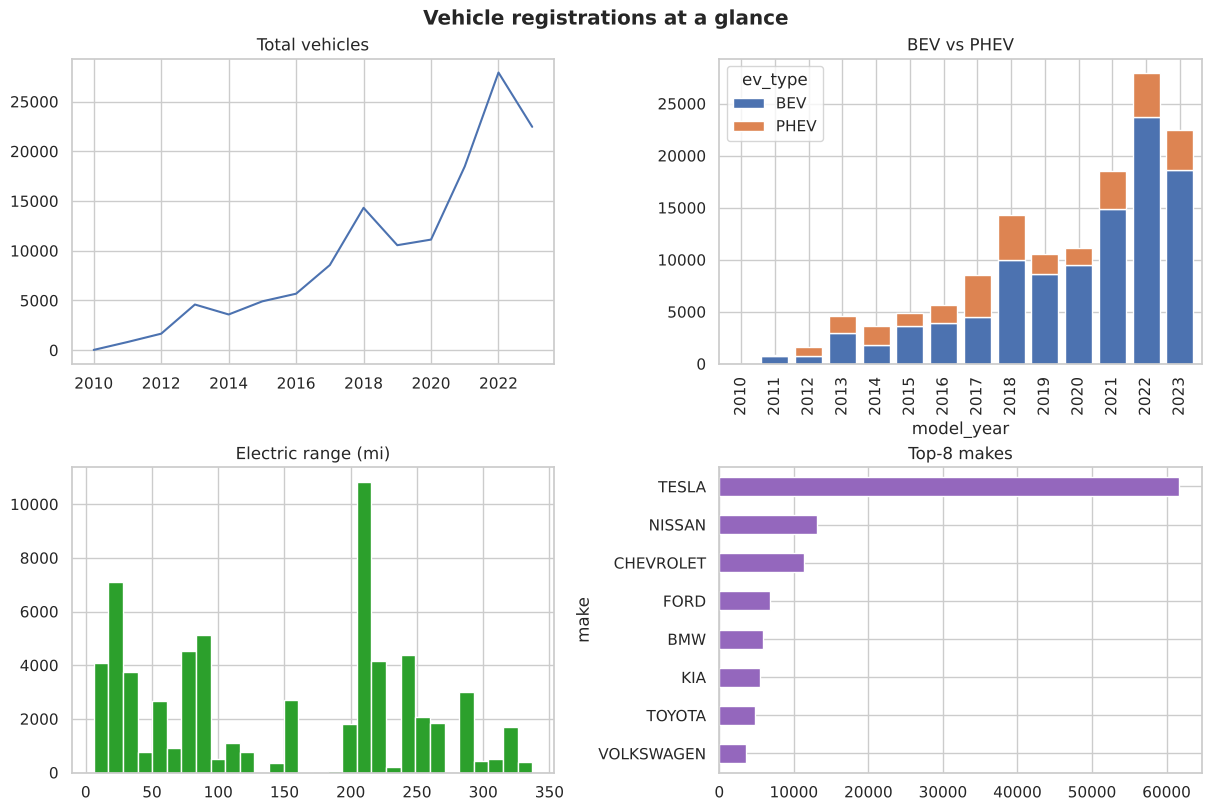

In [22]:
sns.set_theme(style="whitegrid")
reg = ev_t.groupby(["model_year", "ev_type"], observed=True).size().unstack(fill_value=0); reg["Total"] = reg.sum(axis=1)
known = ev_t[(~ev_t["range_imputed"]) & (ev_t["model_year"] <= 2020)].copy()          # real range values only
for c in ["make", "era", "cafv", "ev_type", "range_band"]: known[c] = known[c].cat.remove_unused_categories()
top6 = ev_t["make"].value_counts().head(6).index.tolist()
make_year = ev_t[ev_t["make"].isin(top6)].groupby(["model_year", "make"], observed=True).size().reset_index(name="vehicles")
make_year["make"] = make_year["make"].astype(str)
print(len(known), "vehicles with real range |", top6)

# 5.1 Figures and subplots
fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
ax[0, 0].plot(reg.index, reg["Total"]); ax[0, 0].set_title("Total vehicles")
reg[["BEV", "PHEV"]].plot(kind="bar", stacked=True, ax=ax[0, 1], width=.8); ax[0, 1].set_title("BEV vs PHEV")
ax[1, 0].hist(known["electric_range"], bins=30, color="tab:green", edgecolor="white"); ax[1, 0].set_title("Electric range (mi)")
ev_t["make"].value_counts().head(8).sort_values().plot(kind="barh", ax=ax[1, 1], color="tab:purple"); ax[1, 1].set_title("Top-8 makes")
fig.suptitle("Vehicle registrations at a glance", weight="bold"); plt.show()

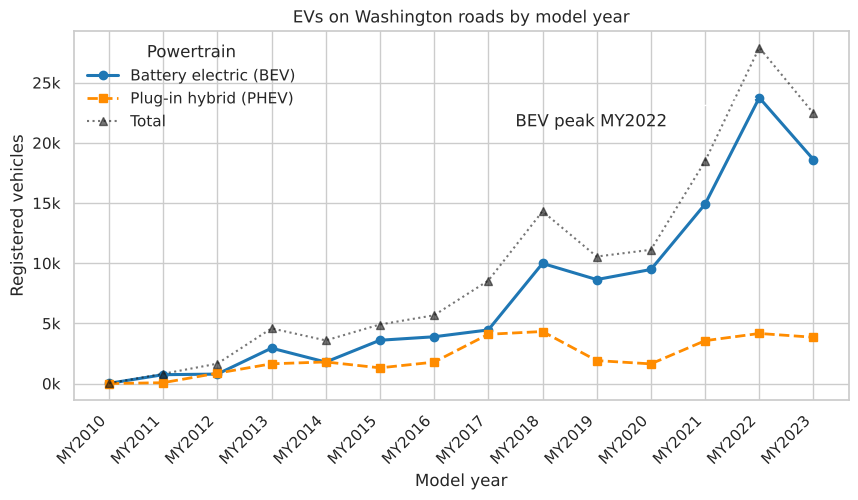

['ev_registrations.pdf', 'ev_registrations.png', 'ev_registrations_by_type.pdf', 'ev_registrations_by_type.png', 'ev_registrations_by_type.svg']


In [23]:
# 5.2 Colours, markers, line styles  |  5.3 Ticks, labels, legends  |  5.4 Saving plots
from matplotlib.ticker import FuncFormatter
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(reg.index, reg["BEV"], color="#1f77b4", marker="o", linestyle="-", lw=2.2, label="Battery electric (BEV)")
ax.plot(reg.index, reg["PHEV"], color="darkorange", marker="s", linestyle="--", lw=2, label="Plug-in hybrid (PHEV)")
ax.plot(reg.index, reg["Total"], "k:", marker="^", alpha=.6, label="Total")
ax.set_xticks(reg.index); ax.set_xticklabels([f"MY{y}" for y in reg.index], rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set(title="EVs on Washington roads by model year", xlabel="Model year", ylabel="Registered vehicles")
ax.legend(loc="upper left", title="Powertrain", frameon=False)
pk = reg["BEV"].idxmax(); ax.annotate(f"BEV peak MY{pk}", (pk, reg["BEV"].max()), (pk - 4.5, reg["BEV"].max() * .9), arrowprops=dict(arrowstyle="->"))
fig.savefig("outputs/ev_registrations.png", dpi=150, bbox_inches="tight"); fig.savefig("outputs/ev_registrations.pdf", bbox_inches="tight")
plt.show(); print(sorted(f for f in os.listdir("outputs") if f.startswith("ev_registrations")))

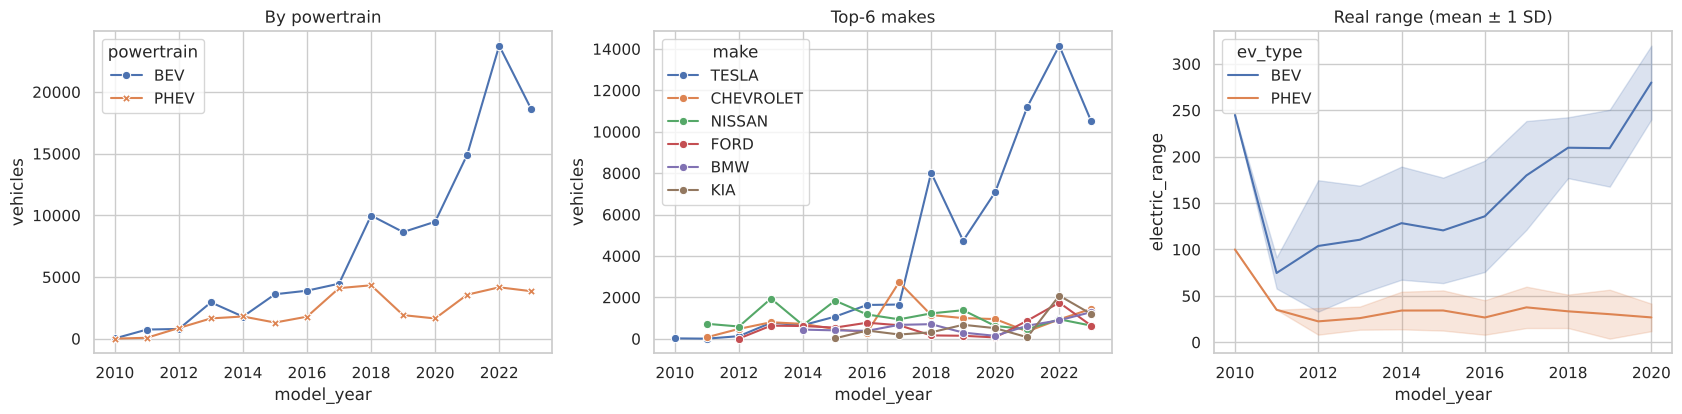

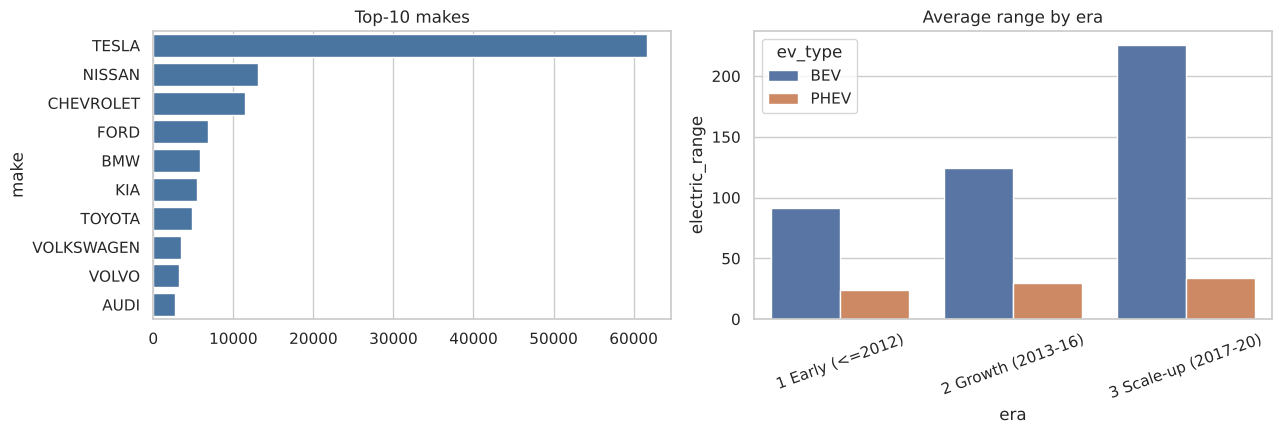

In [24]:
# 5.5 Seaborn line plots
long = reg[["BEV", "PHEV"]].reset_index().melt(id_vars="model_year", var_name="powertrain", value_name="vehicles")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
sns.lineplot(data=long, x="model_year", y="vehicles", hue="powertrain", style="powertrain", markers=True, dashes=False, ax=ax[0]); ax[0].set_title("By powertrain")
sns.lineplot(data=make_year, x="model_year", y="vehicles", hue="make", marker="o", ax=ax[1]); ax[1].set_title("Top-6 makes")
sns.lineplot(data=known, x="model_year", y="electric_range", hue="ev_type", errorbar="sd", ax=ax[2]); ax[2].set_title("Real range (mean ± 1 SD)")
plt.tight_layout(); plt.show()

# 5.6 Seaborn bar plots
top10 = ev_t["make"].value_counts().head(10)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=top10.values, y=top10.index.astype(str), color="#3b75af", ax=ax[0]); ax[0].set_title("Top-10 makes")
sns.barplot(data=known, x="era", y="electric_range", hue="ev_type", errorbar=None, ax=ax[1]); ax[1].set_title("Average range by era"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

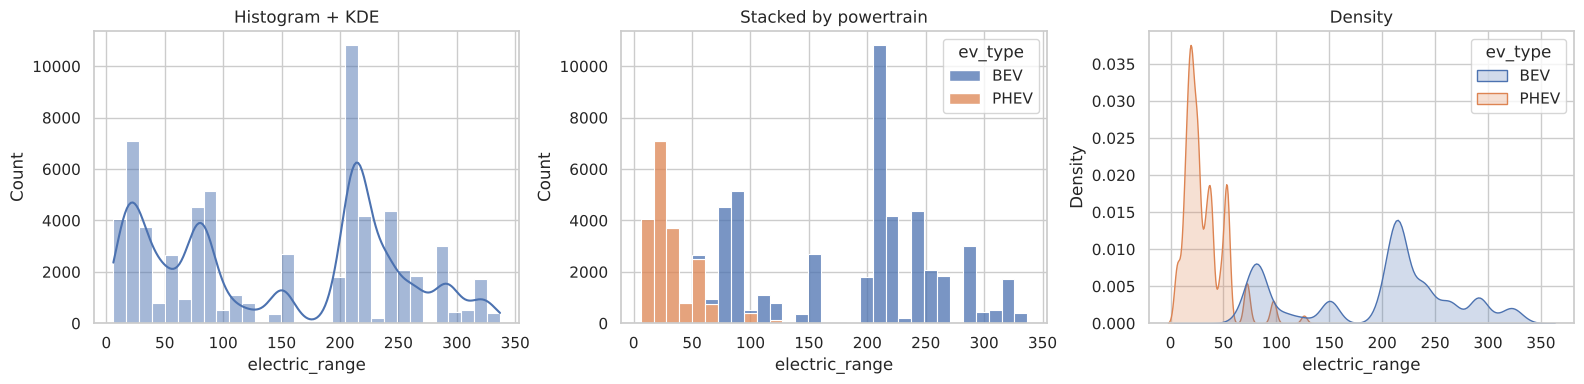

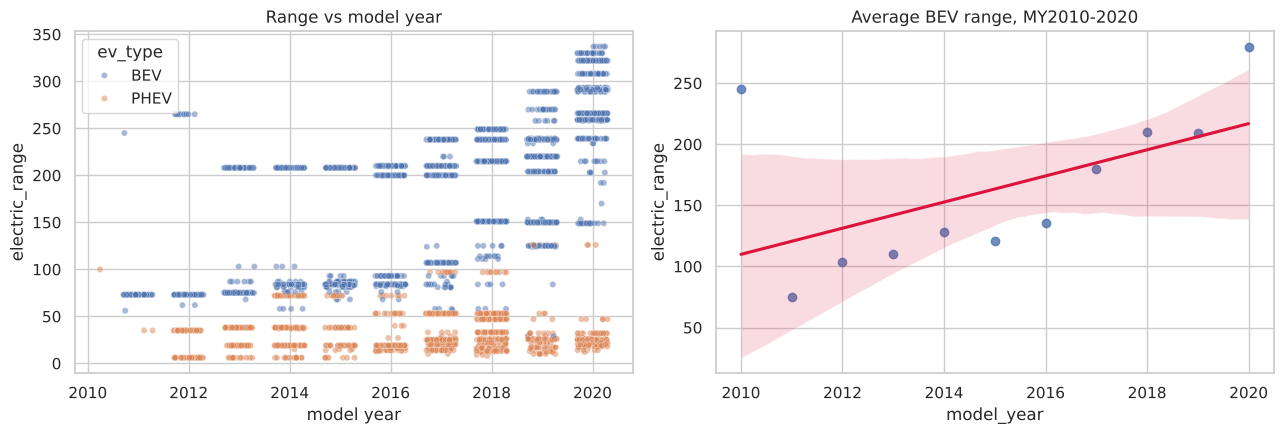

Average BEV range rose ≈ 10.7 miles per model year.


In [25]:
# 5.7 Histograms and density plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(known["electric_range"], bins=30, kde=True, ax=ax[0]); ax[0].set_title("Histogram + KDE")
sns.histplot(data=known, x="electric_range", hue="ev_type", bins=30, multiple="stack", ax=ax[1]); ax[1].set_title("Stacked by powertrain")
sns.kdeplot(data=known, x="electric_range", hue="ev_type", fill=True, common_norm=False, ax=ax[2]); ax[2].set_title("Density")
plt.tight_layout(); plt.show()

# 5.8 Scatter or point plots
smp = known.sample(4000, random_state=0).copy(); smp["yj"] = smp["model_year"] + np.random.default_rng(0).uniform(-.3, .3, len(smp))
yr = known[known["ev_type"] == "BEV"].groupby("model_year")["electric_range"].mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=smp, x="yj", y="electric_range", hue="ev_type", alpha=.5, s=20, ax=ax[0]); ax[0].set_title("Range vs model year"); ax[0].set_xlabel("model year")
sns.regplot(data=yr, x="model_year", y="electric_range", line_kws={"color": "crimson"}, ax=ax[1]); ax[1].set_title("Average BEV range, MY2010-2020")
plt.tight_layout(); plt.show()
print(f"Average BEV range rose ≈ {np.polyfit(yr['model_year'], yr['electric_range'], 1)[0]:.1f} miles per model year.")

### 7.6 Make-by-year pattern — heat-map *(CO5: Seaborn heat-map; Section 7.6 of the report)*
**Concept:** a heat-map shows a make × model-year table in one picture, so we can see *when* each make entered the market and how its volume changed.

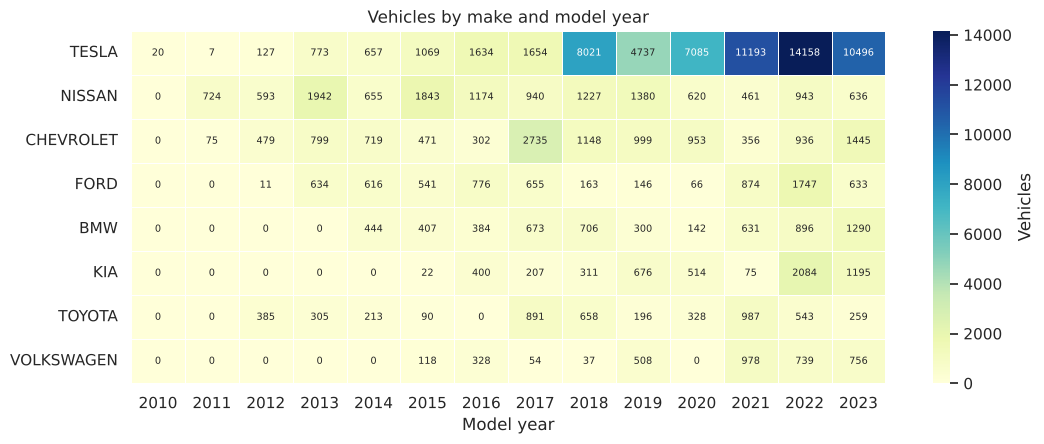

In [26]:
# 7.6 Make-by-year pattern: vehicles by make and model year for the eight largest makes
top8 = ev_t["make"].value_counts().head(8).index.tolist()
hm = (ev_t[ev_t["make"].isin(top8)].groupby(["make", "model_year"], observed=True)
          .size().unstack(fill_value=0).loc[top8])
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(hm, annot=True, fmt="d", cmap="YlGnBu", linewidths=.4, annot_kws={"size": 7}, cbar_kws={"label": "Vehicles"}, ax=ax)
ax.set(title="Vehicles by make and model year", xlabel="Model year", ylabel="")
plt.tight_layout(); plt.savefig("outputs/make_year_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

**Figure 9:** *Vehicles by make and model year for the eight largest makes.*

**Interpretation:** The heat-map shows how each make entered the market. Nissan was the early volume leader (peak 1,942 vehicles in model year 2013), Chevrolet had a spike with the 2017 Bolt, and Tesla’s numbers rise steeply from model year 2018, reaching 14,158 vehicles in 2022. Ford and Kia peak with model year 2022 (1,747 and 2,084 vehicles) and Volkswagen has about 740–980 vehicles in each of the model years 2021–2023.

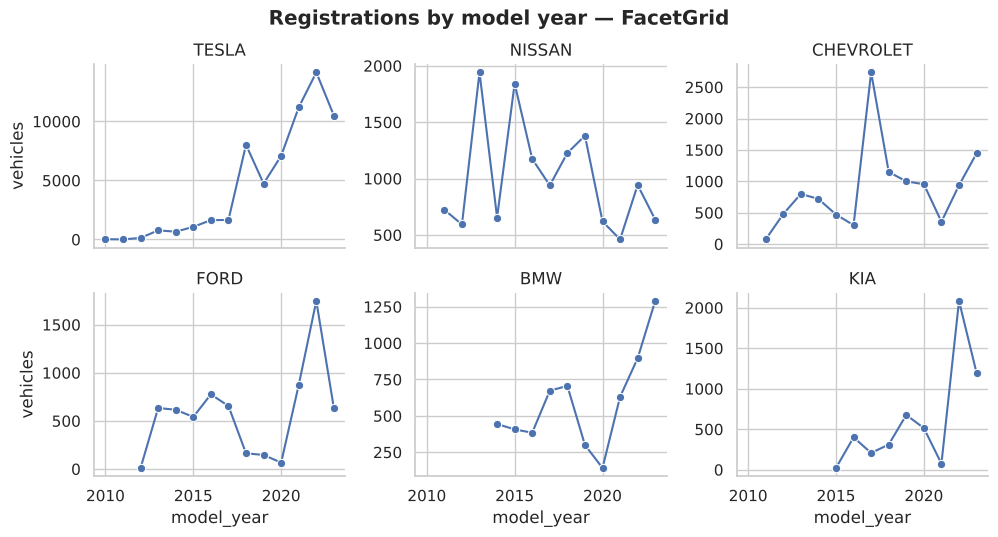

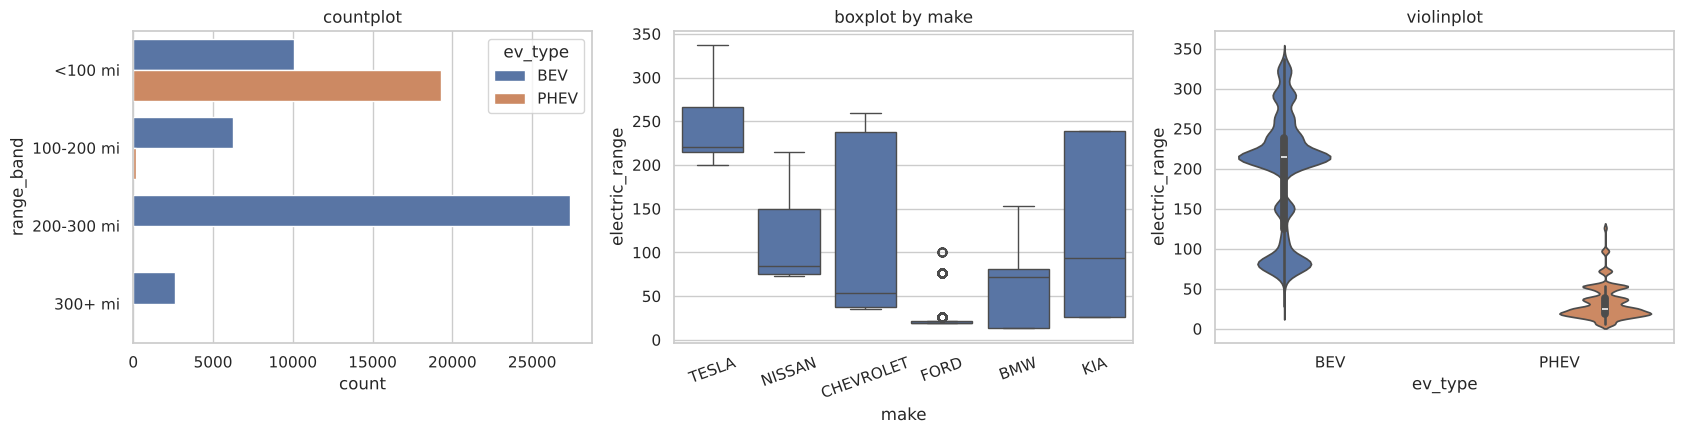

In [27]:
# 5.9 FacetGrid and categorical data
g = sns.FacetGrid(make_year, col="make", col_order=top6, col_wrap=3, height=2.6, aspect=1.3, sharey=False)
g.map_dataframe(sns.lineplot, x="model_year", y="vehicles", marker="o"); g.set_titles("{col_name}")
g.figure.suptitle("Registrations by model year — FacetGrid", y=1.03, weight="bold"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=known, y="range_band", hue="ev_type", ax=ax[0]); ax[0].set_title("countplot")
sns.boxplot(data=known[known["make"].isin(top6)], x="make", y="electric_range", order=top6, ax=ax[1]); ax[1].set_title("boxplot by make"); ax[1].tick_params(axis="x", rotation=20)
sns.violinplot(data=known, x="ev_type", y="electric_range", hue="ev_type", legend=False, ax=ax[2]); ax[2].set_title("violinplot")
plt.tight_layout(); plt.show()

---
# 📌 Findings

In [28]:
tot = len(ev); tm = ev["make"].value_counts(); tc = ev["county"].value_counts()
bk = known[known["ev_type"] == "BEV"].groupby("model_year")["electric_range"].mean()
print(f"1. {tot:,} Washington-registered electric vehicles; BEVs are {(ev['ev_type'] == 'BEV').mean():.1%} of the fleet.")
print(f"2. Model year {reg['Total'].idxmax()} has the most vehicles ({reg['Total'].max():,}); cohort size grew {cagr:.1%} per year from MY2013 to MY2022.")
print(f"3. {tm.index[0]} leads with {tm.iloc[0]/tot:.1%} of vehicles, then {tm.index[1]} and {tm.index[2]}.")
print(f"4. Real BEV range rose from {bk.loc[2013]:.0f} mi (MY2013) to {bk.loc[2020]:.0f} mi (MY2020).")
print(f"5. {tc.index[0]} county holds {tc.iloc[0]/tot:.1%} of the fleet, followed by {tc.index[1]} and {tc.index[2]}.")

1. 134,726 Washington-registered electric vehicles; BEVs are 77.0% of the fleet.
2. Model year 2022 has the most vehicles (27,920); cohort size grew 22.2% per year from MY2013 to MY2022.
3. TESLA leads with 45.8% of vehicles, then NISSAN and CHEVROLET.
4. Real BEV range rose from 111 mi (MY2013) to 280 mi (MY2020).
5. King county holds 52.6% of the fleet, followed by Snohomish and Pierce.


**Limitations:** model year is a proxy for registration time and only currently-registered vehicles appear (survivorship bias); ~42 % of range values are missing in the source (handled as described in 3.4); the origin table in 3.12 is hand-made.

**Source:** Washington State Department of Licensing — Electric Vehicle Population Data.